In [1]:
import sys
import os
import math
from typing import NamedTuple

from matplotlib import pyplot as plt
import numpy as np
import pandas as pd

from sklearn.model_selection import TimeSeriesSplit, StratifiedKFold

import jax
import jax.numpy as jnp
import optax


sys.path.append(os.path.join(os.getcwd(), 'import'))

# noinspection PyUnresolvedReferences
from utils import read_utils
# noinspection PyUnresolvedReferences
from utils import plot_utils
# noinspection PyUnresolvedReferences
from utils import train_utils
# noinspection PyUnresolvedReferences
from utils import artificializer

# noinspection PyUnresolvedReferences
from models import bom
# noinspection PyUnresolvedReferences
from models import hgm

In [2]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)
importlib.reload(artificializer)
importlib.reload(bom)
importlib.reload(hgm)

<module 'models.hgm' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/Work/ZimmerLab/MSc_Thesis/Workspace/hobe/worm-2025-fieseler/import/models/hgm.py'>

# Functions

In [3]:
class Lambdas(NamedTuple):
	loss_lambdas: tuple[float, float]
	reg_lambdas: tuple[float, float]
	cca_lambdas: tuple[float, float]

In [4]:
def separate_losses(file_ids, columns, models_spn_man_rec_res_pres):
	models_spn = [
		[
			pd.DataFrame(data=np.array(split[0])[None], columns=columns[i]) for split in models_spn_man_rec_res_pres[i]
		] for i in range(len(file_ids))
	]
	models_man = [
		[
			pd.DataFrame(data=np.array(split[1]), columns=[f'M{i}' for i in range(np.array(split[1]).shape[1])]) for split in models_spn_man_rec_res_pres[i]
		] for i in range(len(file_ids))
	]
	(models_rec,
	 models_res,
	 models_pres) = tuple(
		[
			[
				pd.DataFrame(data=np.array(split[m]), columns=columns[i]) for split in models_spn_man_rec_res_pres[i]
			] for i in range(len(file_ids))
		] for m in [2, 3, 4]
	)
	return models_spn, models_man, models_rec, models_res, models_pres

In [5]:
def assemble(boms_scores_per_neuron, hgms_scores_per_neuron):
	neurons_labels = [scores_per_neuron[0].columns for scores_per_neuron in hgms_scores_per_neuron]

	boms_scores_per_neuron = [np.array([split.values[0] for split in scores]) for scores in boms_scores_per_neuron]
	hgms_scores_per_neuron = [np.array([split.values[0] for split in scores]) for scores in hgms_scores_per_neuron]

	neuron_scores = dict()
	boms_scores_per_neuron_avg = [np.mean(scores, axis=0) for scores in boms_scores_per_neuron]
	hgms_scores_per_neuron_avg = [np.mean(scores, axis=0) for scores in hgms_scores_per_neuron]
	for label_list, score_bom_list, score_hgm_list in zip(neurons_labels, boms_scores_per_neuron_avg, hgms_scores_per_neuron_avg):
		for i in range(len(label_list)):
			label = label_list[i]
			if label != '' and label[-1] != '_':
				score_bom_new, score_hgm_new = np.array(score_bom_list[i]), np.array(score_hgm_list[i])
				if len(score_hgm_new.shape) == 0:
					score_bom_new = score_bom_new.reshape(1, 1)
					score_hgm_new = score_hgm_new.reshape(1, 1)
				if label not in neuron_scores.keys():
					neuron_scores[label] = (score_bom_new, score_hgm_new)
				else:
					score_bom_prev, score_hgm_prev = neuron_scores[label]
					neuron_scores[label] = (np.vstack([score_bom_prev, score_bom_new]), np.vstack([score_hgm_prev, score_hgm_new]))

	return neuron_scores

# read & prep

In [6]:
selection_n_scores = ['VB02', 'DB01', 'DD01', 'AVBR', 'AVBL',		# paper
					  'RMDDR', 'SMDDR', 'SMDDL',					# C
					  'AVAR', 'AVAL',								# M
					  'ALA', 'AWBR', 'AWBR']						# O
selection_n_traces = ['DB01', 'VB02', 'DD01', 'AVAR', 'ALA']
selection_n_scores = ['AVAR', 'DD01', 'VB02', 'SMDDR']

selection_bhl = ['REV', 'VENTRAL_TURN', 'DORSAL_TURN', 'PAUSE']


dims = 2  # just for the comparison cca


# read_ids = list(range(0, 33+1))
# read_ids = [0, 12, 14, 23, 29, 32]
read_ids = [14]
plot_id = 14


gfp = False
if gfp:
	read_ids_gfp = list(range(0, 7+1))
	# read_ids_gfp = [0]
	plot_id_gfp = 0

artificial = False
if artificial:
	dims_generation = 2
	weights = (0.5, 2.)

In [7]:
# read
path = os.path.join(read_utils.get_data_path(), 'worm-2025-fieseler', 'exported_data_gcamp')
(file_ids_gcamp, filenames_gcamp,
 traces_gcamp,
 continuous_behaviors_gcamp,
 discrete_states_gcamp, eigenworms_gcamp,
 kymographs_gcamp) = read_utils.get_data(path, read_ids)

# clear nan values
for i in range(len(file_ids_gcamp)):
	mask = eigenworms_gcamp[i].notna().all(axis=1)

	traces_gcamp[i] = traces_gcamp[i][mask]
	#continuous_behaviors_gcamp[i] = continuous_behaviors_gcamp[i][mask]
	eigenworms_gcamp[i] = eigenworms_gcamp[i][mask]
	discrete_states_gcamp[i] = discrete_states_gcamp[i][mask]

	#kymographs_gcamp[i] = kymographs_gcamp[i][mask]
	#filenames_gcamp[i] = filenames_gcamp[i][mask]

# remove unused discrete state labels
discrete_states_gcamp = [ds[selection_bhl] for ds in discrete_states_gcamp]

# naive ID unknown neurons
for i in range(len(file_ids_gcamp)):
	traces_gcamp[i].columns = pd.Index([
		f'{file_ids_gcamp[i]:02d}_{n_id:03d}' if empty else label for n_id, (label, empty) in enumerate(zip(traces_gcamp[i].columns, traces_gcamp[i].columns == ''))
	])


if gfp:
	# read
	path_gfp = os.path.join(read_utils.get_data_path(), 'worm-2025-fieseler', 'exported_data_gfp')
	(file_ids_gfp, filenames_gfp,
	 traces_gfp,
	 continuous_behaviors_gfp,
	 discrete_states_gfp, eigenworms_gfp,
	 kymographs_gfp) = read_utils.get_data(path_gfp, read_ids_gfp)

	# clear nan values
	for i in range(len(file_ids_gfp)):
		mask = eigenworms_gfp[i].notna().all(axis=1)

		traces_gfp[i] = traces_gfp[i][mask]
		#continuous_behaviors_gfp[i] = continuous_behaviors_gfp[i][mask]
		eigenworms_gfp[i] = eigenworms_gfp[i][mask]
		discrete_states_gfp[i] = discrete_states_gfp[i][mask]

		#kymographs_gfp[i] = kymographs_gfp[i][mask]
		#filenames_gfp[i] = filenames_gfp[i][mask]

	# remove unused discrete state labels
	discrete_states_gfp = [ds[selection_bhl] for ds in discrete_states_gfp]

	# naive ID unknown neurons
	for i in range(len(file_ids_gfp)):
		traces_gfp[i].columns = pd.Index([
			f'{file_ids_gfp[i]:02d}_{n_id:03d}' if empty else label for n_id, (label, empty) in enumerate(zip(traces_gfp[i].columns, traces_gfp[i].columns == ''))
		])


if artificial:
	file_ids_art = file_ids_gcamp.copy()
	filenames_art = list()

	discrete_states_art = discrete_states_gcamp.copy()
	eigenworms_art = eigenworms_gcamp.copy()

	neural_modes_art = list()
	traces_reconstructed_art = list()
	traces_residual_art = list()

	traces_art = list()

	for i in range(len(file_ids_gcamp)):
		(filename_art,
		 neural_modes_art_,
		 traces_reconstructed_art_,
		 traces_residual_art_,
		 traces_art_,
		 params_art_,
		 params_cca_art_) = artificializer.artificialize(weights, hgm,
														 filenames_gcamp[i],
														 traces_gcamp[i].columns,
														 eigenworms_art[i],
														 discrete_states_art[i],
														 n_dimensions=dims_generation)
		filenames_art.append(filename_art)
		neural_modes_art.append(neural_modes_art_)
		traces_reconstructed_art.append(traces_reconstructed_art_)
		traces_residual_art.append(traces_residual_art_)
		traces_art.append(traces_art_)

# read models

In [8]:
bom_reg_lamdas = {
	# 'w1_reg_lambda': 0.01,
	'w1_reg_lambda': 1E-3,
}
hgm_reg_lamdas = {
	# 'w1_reg_lambda': 0.005,
	# 'w2_reg_lambda': 0.01,
	'w1_reg_lambda': 1E-3,
	'w2_reg_lambda': 1E-5,
}

prefix = ''

In [9]:
bom_load_name_gcamp = os.path.join(prefix, f'boman_gcamp_w1-{bom_reg_lamdas['w1_reg_lambda']:.0E}')
hgm_load_name_gcamp = os.path.join(prefix, f'hgman_gcamp_w1-{hgm_reg_lamdas['w1_reg_lambda']:.0E}_w2-{hgm_reg_lamdas['w2_reg_lambda']:.0E}')

if gfp:
	bom_load_name_gfp = os.path.join(prefix, f'boman_gfp_w1-{bom_reg_lamdas['w1_reg_lambda']:.0E}')
	hgm_load_name_gfp = os.path.join(prefix, f'hgman_gfp_w1-{hgm_reg_lamdas['w1_reg_lambda']:.0E}_w2-{hgm_reg_lamdas['w2_reg_lambda']:.0E}')

if artificial:
	bom_load_name_art = os.path.join(prefix, f'boman_art_w1-{bom_reg_lamdas['w1_reg_lambda']:.0E}')
	hgm_load_name_art = os.path.join(prefix, f'hgman_art_w1-{hgm_reg_lamdas['w1_reg_lambda']:.0E}_w2-{hgm_reg_lamdas['w2_reg_lambda']:.0E}')

In [10]:
boms_params_gcamp = train_utils.load_params(bom_load_name_gcamp, filenames_gcamp)

boms_losses_gcamp_all = train_utils.load_losses(bom_load_name_gcamp, filenames_gcamp)
boms_losses_train_gcamp = [losses[0] for losses in boms_losses_gcamp_all]
boms_man_losses_train_gcamp = [losses[1] for losses in boms_losses_gcamp_all]
boms_res_losses_train_gcamp = [losses[2] for losses in boms_losses_gcamp_all]
boms_mpe_losses_train_gcamp = [losses[3] for losses in boms_losses_gcamp_all]
boms_losses_gcamp = [losses[4] for losses in boms_losses_gcamp_all]
boms_man_losses_gcamp = [losses[5] for losses in boms_losses_gcamp_all]
boms_res_losses_gcamp = [losses[6] for losses in boms_losses_gcamp_all]
boms_mpe_losses_gcamp = [losses[7] for losses in boms_losses_gcamp_all]

hgms_params_gcamp = train_utils.load_params(hgm_load_name_gcamp, filenames_gcamp)

hgms_losses_gcamp_all = train_utils.load_losses(hgm_load_name_gcamp, filenames_gcamp)
hgms_losses_train_gcamp = [losses[0] for losses in hgms_losses_gcamp_all]
hgms_man_losses_train_gcamp = [losses[1] for losses in hgms_losses_gcamp_all]
hgms_res_losses_train_gcamp = [losses[2] for losses in hgms_losses_gcamp_all]
hgms_mpe_losses_train_gcamp = [losses[3] for losses in hgms_losses_gcamp_all]
hgms_losses_gcamp = [losses[4] for losses in hgms_losses_gcamp_all]
hgms_man_losses_gcamp = [losses[5] for losses in hgms_losses_gcamp_all]
hgms_res_losses_gcamp = [losses[6] for losses in hgms_losses_gcamp_all]
hgms_mpe_losses_gcamp = [losses[7] for losses in hgms_losses_gcamp_all]


if gfp:
	boms_params_gfp = train_utils.load_params(bom_load_name_gfp, filenames_gfp)

	boms_losses_gfp_all = train_utils.load_losses(bom_load_name_gfp, filenames_gfp)
	boms_losses_train_gfp = [losses[0] for losses in boms_losses_gfp_all]
	boms_man_losses_train_gfp = [losses[1] for losses in boms_losses_gfp_all]
	boms_res_losses_train_gfp = [losses[2] for losses in boms_losses_gfp_all]
	boms_mpe_losses_train_gfp = [losses[3] for losses in boms_losses_gfp_all]
	boms_losses_gfp = [losses[4] for losses in boms_losses_gfp_all]
	boms_man_losses_gfp = [losses[5] for losses in boms_losses_gfp_all]
	boms_res_losses_gfp = [losses[6] for losses in boms_losses_gfp_all]
	boms_mpe_losses_gfp = [losses[7] for losses in boms_losses_gfp_all]

	hgms_params_gfp = train_utils.load_params(hgm_load_name_gfp, filenames_gfp)

	hgms_losses_gfp_all = train_utils.load_losses(hgm_load_name_gfp, filenames_gfp)
	hgms_losses_train_gfp = [losses[0] for losses in hgms_losses_gfp_all]
	hgms_man_losses_train_gfp = [losses[1] for losses in hgms_losses_gfp_all]
	hgms_res_losses_train_gfp = [losses[2] for losses in hgms_losses_gfp_all]
	hgms_mpe_losses_train_gfp = [losses[3] for losses in hgms_losses_gfp_all]
	hgms_losses_gfp = [losses[4] for losses in hgms_losses_gfp_all]
	hgms_man_losses_gfp = [losses[5] for losses in hgms_losses_gfp_all]
	hgms_res_losses_gfp = [losses[6] for losses in hgms_losses_gfp_all]
	hgms_mpe_losses_gfp = [losses[7] for losses in hgms_losses_gfp_all]


if artificial:
	boms_params_art = train_utils.load_params(bom_load_name_art, filenames_art)

	boms_losses_art_all = train_utils.load_losses(bom_load_name_art, filenames_art)
	boms_losses_train_art = [losses[0] for losses in boms_losses_art_all]
	boms_man_losses_train_art = [losses[1] for losses in boms_losses_art_all]
	boms_res_losses_train_art = [losses[2] for losses in boms_losses_art_all]
	boms_mpe_losses_train_art = [losses[3] for losses in boms_losses_art_all]
	boms_losses_art = [losses[4] for losses in boms_losses_art_all]
	boms_man_losses_art = [losses[5] for losses in boms_losses_art_all]
	boms_res_losses_art = [losses[6] for losses in boms_losses_art_all]
	boms_mpe_losses_art = [losses[7] for losses in boms_losses_art_all]

	hgms_params_art = train_utils.load_params(hgm_load_name_art, filenames_art)

	hgms_losses_art_all = train_utils.load_losses(hgm_load_name_art, filenames_art)
	hgms_losses_train_art = [losses[0] for losses in hgms_losses_art_all]
	hgms_man_losses_train_art = [losses[1] for losses in hgms_losses_art_all]
	hgms_res_losses_train_art = [losses[2] for losses in hgms_losses_art_all]
	hgms_mpe_losses_train_art = [losses[3] for losses in hgms_losses_art_all]
	hgms_losses_art = [losses[4] for losses in hgms_losses_art_all]
	hgms_man_losses_art = [losses[5] for losses in hgms_losses_art_all]
	hgms_res_losses_art = [losses[6] for losses in hgms_losses_art_all]
	hgms_mpe_losses_art = [losses[7] for losses in hgms_losses_art_all]

# artificial

### losses

In [11]:
if artificial:
	plot_utils.plot_losses_splits('art hgm vs bom: train',
								  filenames_art,
								  hgms_losses_train_art, boms_losses_train_art,
								  ylimits=None)

In [12]:
if artificial:
	pass

### predict & score

In [13]:
if artificial:
	splits_art = [list(StratifiedKFold(n_splits=5, shuffle=False).split(np.zeros(traces_art[i].shape[0]), discrete_states_art[i]['REV'].values)) for i in range(len(file_ids_art))]

In [14]:
if artificial:
	boms_spn_man_rec_res_pres_art = [[
		bom.score_fn(params, traces_art[i].values[eval], eigenworms_art[i].values[eval]) for params, (train, eval) in zip(boms_params_art[i], splits_art[i])
	] for i in range(len(file_ids_art))]

	hgms_spn_man_rec_res_pres_art = [[
		hgm.score_fn(params, traces_art[i].values[eval], eigenworms_art[i].values[eval]) for params, (train, eval) in zip(hgms_params_art[i], splits_art[i])
	] for i in range(len(file_ids_art))]

	(boms_spn_art,
	 boms_man_art,
	 boms_rec_art,
	 boms_res_art,
	 boms_pres_art) = separate_losses(file_ids_art, [trace.columns for trace in traces_art], boms_spn_man_rec_res_pres_art)

	(hgms_spn_art,
	 hgms_man_art,
	 hgms_rec_art,
	 hgms_res_art,
	 hgms_pres_art) = separate_losses(file_ids_art, [trace.columns for trace in traces_art], hgms_spn_man_rec_res_pres_art)

In [15]:
if artificial:
	neuron_scores_art = assemble(boms_spn_art, hgms_spn_art)

In [16]:
if artificial:
	plot_utils.plot_performance_plot(neuron_scores_art, None,
									 title='scores for all neurons', limits=(-0.55, 0.55, -0.55, 0.55))

In [17]:
if artificial:
	plot_utils.plot_performance_plot({key: neuron_scores_art[key] for key in neuron_scores_art if not key[0].isdigit()}, None,
									 title='scores for ID\'d neurons', limits=(-0.55, 0.55, -0.55, 0.55))

### traces

In [18]:
if artificial:
	boms_spn_man_rec_res_pres_art = [[
		bom.score_fn(params, traces_art[i].values, eigenworms_art[i].values) for params in boms_params_art[i]
	] for i in range(len(file_ids_art))]

	hgms_spn_man_rec_res_pres_art = [[
		hgm.score_fn(params, traces_art[i].values, eigenworms_art[i].values) for params in hgms_params_art[i]
	] for i in range(len(file_ids_art))]

	(boms_spn_art_all,
	 boms_man_art_all,
	 boms_rec_art_all,
	 boms_res_art_all,
	 boms_pres_art_all) = separate_losses(file_ids_art, [trace.columns for trace in traces_art], boms_spn_man_rec_res_pres_art)

	(hgms_spn_art_all,
	 hgms_man_art_all,
	 hgms_rec_art_all,
	 hgms_res_art_all,
	 hgms_pres_art_all) = separate_losses(file_ids_art, [trace.columns for trace in traces_art], hgms_spn_man_rec_res_pres_art)

In [19]:
if artificial:
	art_neuron_mean_hgms = {key: np.mean(neuron_scores_art[key][1]) for key in neuron_scores_art.keys()}
	art_selection_n_hgms = [key for _, key in reversed(sorted(zip(art_neuron_mean_hgms.values(), art_neuron_mean_hgms.keys())))]

In [20]:
if artificial:
	art_selection_n_traces_ids_ = [label for label in art_selection_n_hgms if not label[0].isdigit()][:5]
	art_selection_n_traces_ids = [n for n in art_selection_n_traces_ids_ if n in traces_art[file_ids_art.index(plot_id)].keys()]

In [21]:
if artificial:
	splits = 5
	plot_utils.plot_traces_x_splits(
		f'{filenames_art[file_ids_art.index(plot_id)]} art hgm & bom definitions manifold',
		discrete_states_art[file_ids_art.index(plot_id)][['REV']],
		traces_art[file_ids_art.index(plot_id)][art_selection_n_traces_ids],
		[hgms_rec_art_all[file_ids_art.index(plot_id)][i][art_selection_n_traces_ids] for i in range(splits)],
		[boms_rec_art_all[file_ids_art.index(plot_id)][i][art_selection_n_traces_ids] for i in range(splits)],
		plot_first=True, plots_per_row=1, ylimits=None)

In [22]:
if artificial:
	splits = 5
	plot_utils.plot_traces_x_splits(
		f'{filenames_art[file_ids_art.index(plot_id)]} art hgm & bom definitions residuals',
		discrete_states_art[file_ids_art.index(plot_id)][['REV']],
		traces_art[file_ids_art.index(plot_id)][art_selection_n_traces_ids],
		[hgms_res_art_all[file_ids_art.index(plot_id)][i][art_selection_n_traces_ids] for i in range(splits)],
		[boms_res_art_all[file_ids_art.index(plot_id)][i][art_selection_n_traces_ids] for i in range(splits)],
		plot_first=True, plots_per_row=1, ylimits=None)

In [23]:
if artificial:
	for i in range(5):
		plot_utils.plot_traces_comparisons(
			f'{filenames_art[file_ids_art.index(plot_id)]} split {i} art hgm & bom predictions residuals',
			discrete_states_art[file_ids_art.index(plot_id)][['REV']],
			traces_art[file_ids_art.index(plot_id)][art_selection_n_traces_ids],
			[hgms_res_art_all[file_ids_art.index(plot_id)][i][art_selection_n_traces_ids],
			 hgms_pres_art_all[file_ids_art.index(plot_id)][i][art_selection_n_traces_ids]],
			[boms_res_art_all[file_ids_art.index(plot_id)][i][art_selection_n_traces_ids],
			 boms_pres_art_all[file_ids_art.index(plot_id)][i][art_selection_n_traces_ids]],
			plot_first=False, plots_per_row=1, ylimits=(-1, 1))

 # gcamp

### predict & score

In [24]:
splits_gcamp = [list(StratifiedKFold(n_splits=5, shuffle=False).split(np.zeros(traces_gcamp[i].shape[0]), discrete_states_gcamp[i]['REV'].values)) for i in range(len(file_ids_gcamp))]

In [25]:
boms_spn_man_rec_res_pres_gcamp = [[
	bom.score_fn(params, traces_gcamp[i].values[eval], eigenworms_gcamp[i].values[eval]) for params, (train, eval) in zip(boms_params_gcamp[i], splits_gcamp[i])
] for i in range(len(file_ids_gcamp))]

hgms_spn_man_rec_res_pres_gcamp = [[
	hgm.score_fn(params, traces_gcamp[i].values[eval], eigenworms_gcamp[i].values[eval]) for params, (train, eval) in zip(hgms_params_gcamp[i], splits_gcamp[i])
] for i in range(len(file_ids_gcamp))]

(boms_spn_gcamp,
 boms_man_gcamp,
 boms_rec_gcamp,
 boms_res_gcamp,
 boms_pres_gcamp) = separate_losses(file_ids_gcamp, [trace.columns for trace in traces_gcamp], boms_spn_man_rec_res_pres_gcamp)

(hgms_spn_gcamp,
 hgms_man_gcamp,
 hgms_rec_gcamp,
 hgms_res_gcamp,
 hgms_pres_gcamp) = separate_losses(file_ids_gcamp, [trace.columns for trace in traces_gcamp], hgms_spn_man_rec_res_pres_gcamp)

### losses

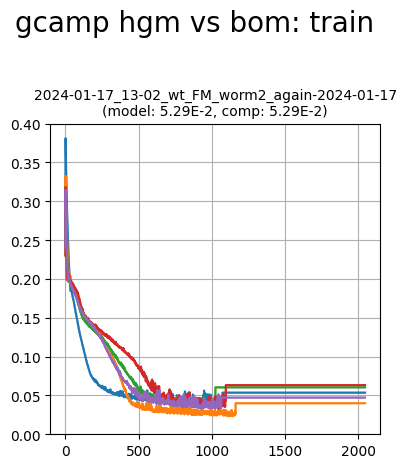

In [26]:
plot_utils.plot_losses_splits('gcamp hgm vs bom: train',
							  filenames_gcamp,
							  hgms_losses_train_gcamp, boms_losses_train_gcamp,
							  ylimits=None)

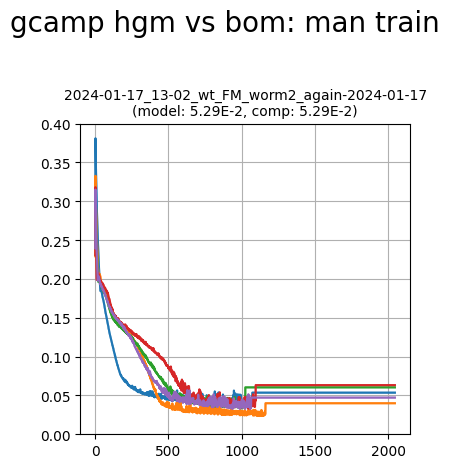

In [27]:
plot_utils.plot_losses_splits('gcamp hgm vs bom: man train',
							  filenames_gcamp,
							  hgms_man_losses_train_gcamp, boms_man_losses_train_gcamp,
							  ylimits=None)

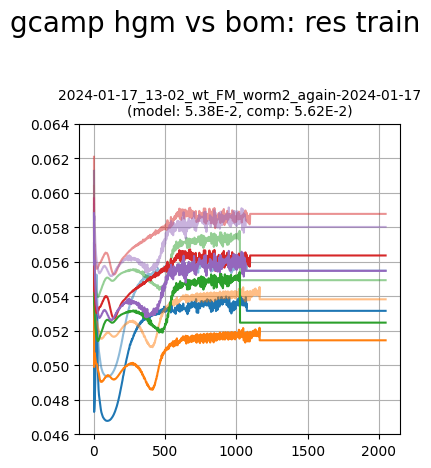

In [28]:
plot_utils.plot_losses_splits('gcamp hgm vs bom: res train',
							  filenames_gcamp,
							  hgms_res_losses_train_gcamp, boms_res_losses_train_gcamp,
							  ylimits=None)

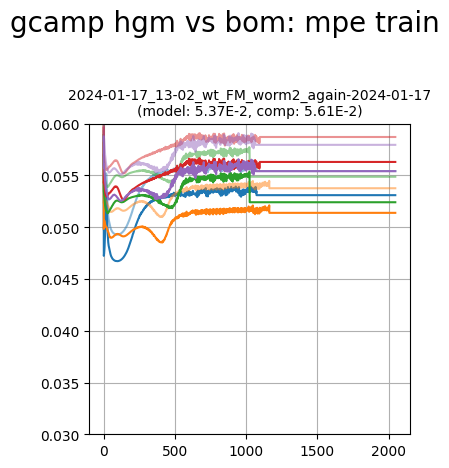

In [29]:
plot_utils.plot_losses_splits('gcamp hgm vs bom: mpe train',
							  filenames_gcamp,
							  hgms_mpe_losses_train_gcamp, boms_mpe_losses_train_gcamp,
							  ylimits=(0.03, 0.06))

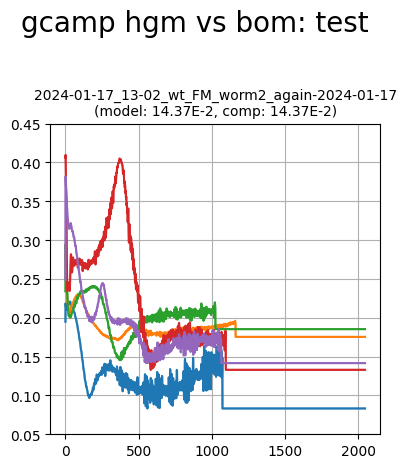

In [30]:
plot_utils.plot_losses_splits('gcamp hgm vs bom: test',
							  filenames_gcamp,
							  hgms_losses_gcamp, boms_losses_gcamp,
							  ylimits=None)

In [31]:
# plot_utils.plot_losses_splits('gcamp hgm vs bom: man test',
# 							  filenames_gcamp,
# 							  hgms_man_losses_gcamp, boms_man_losses_gcamp,
# 							  ylimits=None)

In [32]:
# plot_utils.plot_losses_splits('gcamp hgm vs bom: res test',
# 							  filenames_gcamp,
# 							  hgms_res_losses_gcamp, boms_res_losses_gcamp,
# 							  ylimits=None)

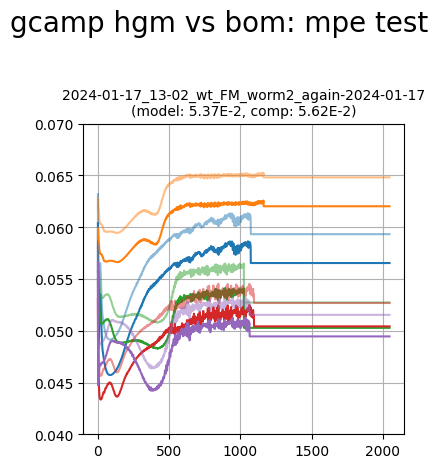

In [33]:
plot_utils.plot_losses_splits('gcamp hgm vs bom: mpe test',
							  filenames_gcamp,
							  hgms_mpe_losses_gcamp, boms_mpe_losses_gcamp,
							  ylimits=(0.04, 0.07))

### performance

In [34]:
neuron_scores_gcamp = assemble(boms_spn_gcamp, hgms_spn_gcamp)

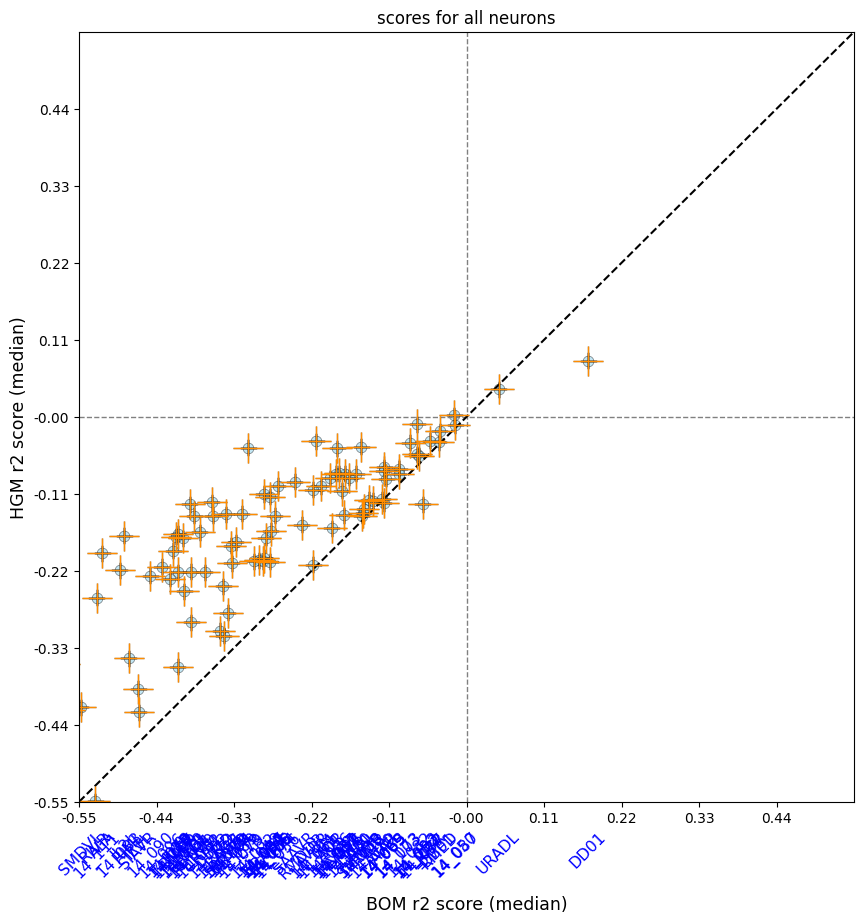

In [35]:
plot_utils.plot_performance_plot(neuron_scores_gcamp, None,
								 title='scores for all neurons', limits=(-0.55, 0.55, -0.55, 0.55))

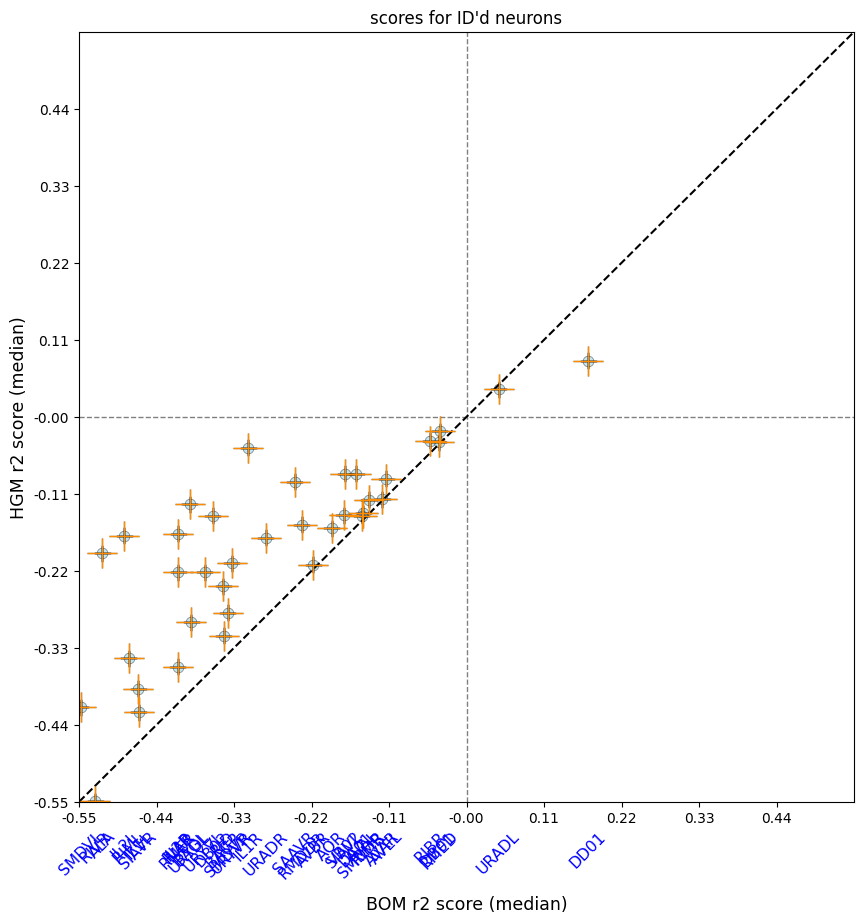

In [36]:
plot_utils.plot_performance_plot({key: neuron_scores_gcamp[key] for key in neuron_scores_gcamp if not key[0].isdigit()}, None,
								 title='scores for ID\'d neurons', limits=(-0.55, 0.55, -0.55, 0.55))

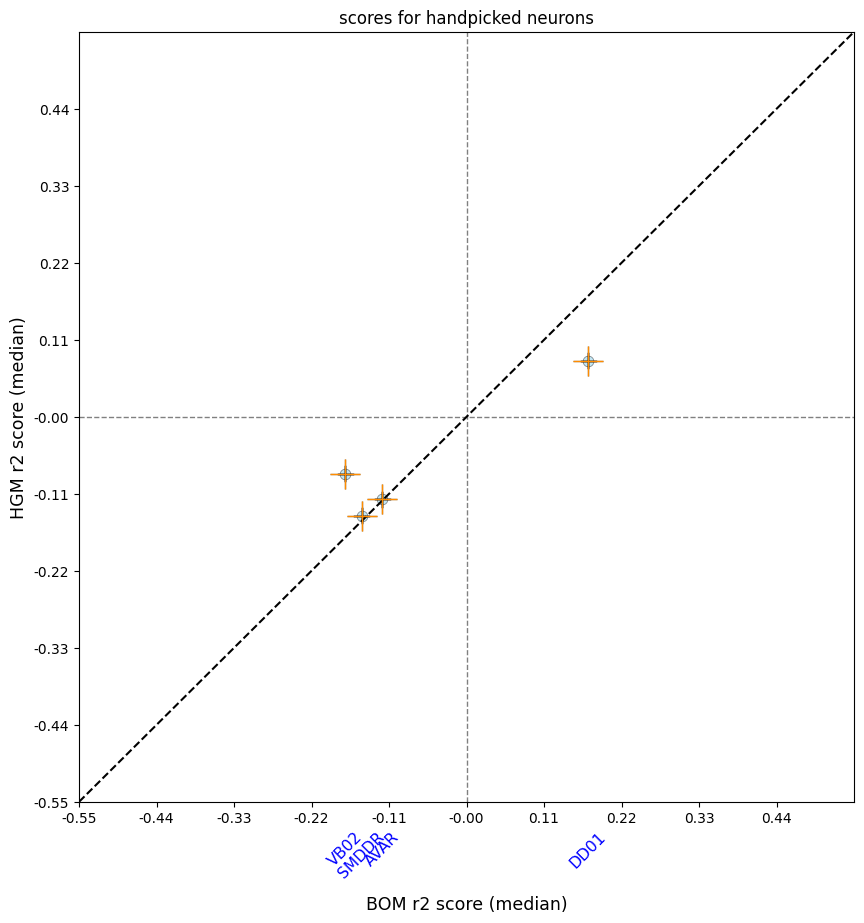

In [37]:
plot_utils.plot_performance_plot({key: neuron_scores_gcamp[key] for key in selection_n_scores if key in neuron_scores_gcamp.keys()}, None,
								 title='scores for handpicked neurons', limits=(-0.55, 0.55, -0.55, 0.55))

# TEMPORARY OLD

## OLD PARAMS WITH NEW SCORING

In [38]:
importlib.reload(train_utils)
importlib.reload(bom)
importlib.reload(hgm)

<module 'models.hgm' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/Work/ZimmerLab/MSc_Thesis/Workspace/hobe/worm-2025-fieseler/import/models/hgm.py'>

In [39]:
hgms_params_gcamp_old = train_utils.load_params('old-full-2d-man-evalzsc/hgm_gcamp_w1-1E-03_w2-1E-05', [f'split_{i}' for i in range(6)])
boms_params_gcamp_old = train_utils.load_params('old-full-2d-man-evalzsc/bom_gcamp_w1-1E-03_w2-1E-05', [f'split_{i}' for i in range(6)])

FileNotFoundError: [Errno 2] No such file or directory: './out/models/old-full-2d-man-evalzsc/hgm_gcamp_w1-1E-03_w2-1E-05/params/split_0.msgpack'

In [ ]:
for i in range(len(filenames_gcamp)):
	for s in range(5):
		hgms_params_gcamp_old[i][s]['prep'] = hgms_params_gcamp[i][s]['prep']
		hgms_params_gcamp_old[i][s]['model'] = {
			'U': hgms_params_gcamp_old[i][s]['U'],
			'V': hgms_params_gcamp_old[i][s]['V'],
			'W1': hgms_params_gcamp_old[i][s]['W1'],
			'W2': hgms_params_gcamp_old[i][s]['W2'],
		}

	for s in range(5):
		boms_params_gcamp_old[i][s]['prep'] = boms_params_gcamp[i][s]['prep']
		boms_params_gcamp_old[i][s]['model'] = {
			'U': boms_params_gcamp_old[i][s]['U'],
			'V': boms_params_gcamp_old[i][s]['V'],
			'W': boms_params_gcamp_old[i][s]['W'],
		}

In [ ]:
boms_spn_man_rec_res_pres_gcamp_old = [[
	bom.score_fn(params, traces_gcamp[i].values[eval], eigenworms_gcamp[i].values[eval]) for params, (train, eval) in zip(boms_params_gcamp_old[i], splits_gcamp[i])
] for i in range(len(file_ids_gcamp))]

hgms_spn_man_rec_res_pres_gcamp_old = [[
	hgm.score_fn(params, traces_gcamp[i].values[eval], eigenworms_gcamp[i].values[eval]) for params, (train, eval) in zip(hgms_params_gcamp_old[i], splits_gcamp[i])
] for i in range(len(file_ids_gcamp))]

(boms_spn_gcamp_old,
 boms_man_gcamp_old,
 boms_rec_gcamp_old,
 boms_res_gcamp_old,
 boms_pres_gcamp_old) = separate_losses(file_ids_gcamp, [trace.columns for trace in traces_gcamp], boms_spn_man_rec_res_pres_gcamp_old)

(hgms_spn_gcamp_old,
 hgms_man_gcamp_old,
 hgms_rec_gcamp_old,
 hgms_res_gcamp_old,
 hgms_pres_gcamp_old) = separate_losses(file_ids_gcamp, [trace.columns for trace in traces_gcamp], hgms_spn_man_rec_res_pres_gcamp_old)

In [ ]:
neuron_scores_gcamp_old = assemble(boms_spn_gcamp_old, hgms_spn_gcamp_old)

In [ ]:
plot_utils.plot_performance_plot({key: neuron_scores_gcamp_old[key] for key in selection_n_scores if key in neuron_scores_gcamp_old.keys()}, None,
								 title='scores for handpicked neurons', limits=(-0.55, 0.55, -0.55, 0.55))

In [ ]:
class PrepData(NamedTuple):
	N_mean: tuple[float, ...]
	N_std: tuple[float, ...]
	B_hl_mean: tuple[float, ...] | None = None
	B_hl_std: tuple[float, ...] | None = None


filenames = filenames_gcamp
traces = traces_gcamp
discrete_states = discrete_states_gcamp
eigenworms = eigenworms_gcamp


SCORES_OLD_HGM = list()
SCORES_OLD_BOM = list()
for i in range(len(filenames)):
	print(f'\n{i+1}/{len(filenames)}: {filenames[i]} ', end='')
	splits = list(StratifiedKFold(n_splits=5).split(np.zeros(traces[i].shape[0]), discrete_states[i]['REV'].values))
	neuron_scores_per_split_hgm = list()
	neuron_scores_per_split_bom = list()

	N = traces[i].values
	B_hl = discrete_states[i].values
	B_ll = eigenworms[i].values

	for s_id, (train, eval) in enumerate(splits):
		N_train, N_eval = jnp.array(N[train]), jnp.array(N[eval])
		B_hl_train, B_hl_eval = jnp.array(B_hl[train]), jnp.array(B_hl[eval])
		B_ll_train, B_ll_eval = jnp.array(B_ll[train]), jnp.array(B_ll[eval])

		prep_data_train = PrepData(
			N_mean=tuple((map(float, N_train.mean(axis=0)))),
			N_std=tuple((map(float, jnp.where((N_std := jnp.std(N_train, axis=0)) == 0.0, 1.0, N_std)))),
			B_hl_mean=tuple((map(float, B_hl_train.mean(axis=0)))),
			B_hl_std=tuple((map(float, jnp.where((B_hl_std := jnp.std(B_hl_train, axis=0)) == 0.0, 1.0, B_hl_std))))
		)
		prep_data_eval = PrepData(
			N_mean=tuple((map(float, N_eval.mean(axis=0)))),
			N_std=tuple((map(float, jnp.where((N_std := jnp.std(N_eval, axis=0)) == 0.0, 1.0, N_std)))),
			B_hl_mean=tuple((map(float, B_hl_eval.mean(axis=0)))),
			B_hl_std=tuple((map(float, jnp.where((B_hl_std := jnp.std(B_hl_eval, axis=0)) == 0.0, 1.0, B_hl_std))))
		)

		params_hgm = hgms_params_gcamp_old[i][s_id]
		params_bom = boms_params_gcamp_old[i][s_id]

		score_per_neuron_hgm = hgm.score_fn_OLD(params_hgm, N_eval, B_ll_eval, prep_data_train)
		neuron_scores_per_split_hgm.append(score_per_neuron_hgm)

		score_per_neuron_bom = bom.score_fn_OLD(params_bom, N_eval, B_ll_eval, prep_data_train)
		neuron_scores_per_split_bom.append(score_per_neuron_bom)

	SCORES_OLD_HGM.append(neuron_scores_per_split_hgm)
	SCORES_OLD_BOM.append(neuron_scores_per_split_bom)

In [ ]:
def assemble_OLD(filenames, traces, bom_models_scores, hgm_models_scores):
	neurons_labels = [traces[i].columns for i in range(len(filenames))]

	neuron_scores = dict()
	bom_models_avg_scores = [np.mean(scores, axis=0) for scores in bom_models_scores]
	hgm_models_avg_scores = [np.mean(scores, axis=0) for scores in hgm_models_scores]
	for label_list, score_bom_list, score_hgm_list in zip(neurons_labels, bom_models_avg_scores, hgm_models_avg_scores):
		for i in range(len(label_list)):
			label = label_list[i]
			if label != '' and label[-1] != '_':
				score_bom_new, score_hgm_new = np.array(score_bom_list[i]), np.array(score_hgm_list[i])
				if len(score_hgm_new.shape) == 0:
					score_bom_new = score_bom_new.reshape(1, 1)
					score_hgm_new = score_hgm_new.reshape(1, 1)
				if label not in neuron_scores.keys():
					neuron_scores[label] = (score_bom_new, score_hgm_new)
				else:
					score_bom_prev, score_hgm_prev = neuron_scores[label]
					neuron_scores[label] = (np.vstack([score_bom_prev, score_bom_new]), np.vstack([score_hgm_prev, score_hgm_new]))

	return neuron_scores



SCORES_OLD = assemble_OLD(filenames_gcamp, traces_gcamp, SCORES_OLD_BOM, SCORES_OLD_HGM)

In [ ]:
selection_n_scores = ['AVAR', 'DD01', 'VB02', 'SMDDR']

plot_utils.plot_performance_plot({key: SCORES_OLD[key] for key in selection_n_scores if key in SCORES_OLD.keys()}, None,
								 title='scores for handpicked neurons', limits=(-0.55, 0.55, -0.55, 0.55))

# ======================

# gfp

### predict & score

In [ ]:
splits_gfp = [list(StratifiedKFold(n_splits=5, shuffle=False).split(np.zeros(traces_gfp[i].shape[0]), discrete_states_gfp[i][['REV']].values)) for i in range(len(file_ids_gfp))]

In [ ]:
boms_spn_man_rec_res_pres_gfp = [[
	bom.score_fn(params, traces_gfp[i].values[eval], eigenworms_gfp[i].values[eval]) for params, (train, eval) in zip(boms_params_gfp[i], splits_gfp[i])
] for i in range(len(file_ids_gfp))]

hgms_spn_man_rec_res_pres_gfp = [[
	hgm.score_fn(params, traces_gfp[i].values[eval], eigenworms_gfp[i].values[eval]) for params, (train, eval) in zip(hgms_params_gfp[i], splits_gfp[i])
] for i in range(len(file_ids_gfp))]

(boms_spn_gfp,
 boms_man_gfp,
 boms_rec_gfp,
 boms_res_gfp,
 boms_pres_gfp) = separate_losses(file_ids_gfp, [trace.columns for trace in traces_gfp], boms_spn_man_rec_res_pres_gfp)

(hgms_spn_gfp,
 hgms_man_gfp,
 hgms_rec_gfp,
 hgms_res_gfp,
 hgms_pres_gfp) = separate_losses(file_ids_gfp, [trace.columns for trace in traces_gfp], hgms_spn_man_rec_res_pres_gfp)

### performance

In [ ]:
if gfp:
	neuron_scores_gfp = assemble(boms_spn_gfp, hgms_spn_gfp)

In [ ]:
if gfp:
	plot_utils.plot_performance_plot(neuron_scores_gcamp, neuron_scores_gfp,
									 title='scores for all neurons (+ GFP)', limits=(-0.55, 0.55, -0.55, 0.55))

In [ ]:
if gfp:
	high_score_hgm_gfp = np.quantile(np.concatenate([pair[1] for pair in neuron_scores_gfp.values()]), 0.95)

	neuron_scores_gcamp_signi = dict()
	for key in neuron_scores_gcamp.keys():
		scores_glm, scores_hgm = neuron_scores_gcamp[key]
		if len(scores_hgm.shape) == 0:
			scores_glm = scores_glm.reshape(1, 1)
			scores_hgm = scores_hgm.reshape(1, 1)

		y = np.median(scores_hgm)
		if y > high_score_hgm_gfp:
			neuron_scores_gcamp_signi[key] = (scores_glm, scores_hgm)

In [ ]:
if gfp:
	plot_utils.plot_performance_plot(neuron_scores_gcamp_signi, None,
									 title='scores for significant neurons', limits=None)

In [ ]:
if gfp:
	plot_utils.plot_performance_plot({key: neuron_scores_gcamp_signi[key] for key in neuron_scores_gcamp_signi if not key[0].isdigit()}, None,
									 title='scores for significant ID\'d neurons', limits=None)

In [ ]:
if gfp:
	plot_utils.plot_improvement_plot_y(neuron_scores_gcamp_signi, None,
									   title='score improvements for significant neurons', limits=None)

In [ ]:
if gfp:
	plot_utils.plot_improvement_plot_y({key: neuron_scores_gcamp_signi[key] for key in neuron_scores_gcamp_signi.keys() if not key[0].isdigit()}, None,
									   title='score improvements for significant ID\'d neurons', limits=None)

# traces

### predict for whole data

In [40]:
boms_spn_man_rec_res_pres_gcamp = [[
	bom.score_fn(params, traces_gcamp[i].values, eigenworms_gcamp[i].values) for params in boms_params_gcamp[i]
] for i in range(len(file_ids_gcamp))]

hgms_spn_man_rec_res_pres_gcamp = [[
	hgm.score_fn(params, traces_gcamp[i].values, eigenworms_gcamp[i].values) for params in hgms_params_gcamp[i]
] for i in range(len(file_ids_gcamp))]

(boms_spn_gcamp_all,
 boms_man_gcamp_all,
 boms_rec_gcamp_all,
 boms_res_gcamp_all,
 boms_pres_gcamp_all) = separate_losses(file_ids_gcamp, [trace.columns for trace in traces_gcamp], boms_spn_man_rec_res_pres_gcamp)

(hgms_spn_gcamp_all,
 hgms_man_gcamp_all,
 hgms_rec_gcamp_all,
 hgms_res_gcamp_all,
 hgms_pres_gcamp_all) = separate_losses(file_ids_gcamp, [trace.columns for trace in traces_gcamp], hgms_spn_man_rec_res_pres_gcamp)

### IDd neurons

In [ ]:
# raise Exception

In [41]:
neuron_signi_mean_impr = {key: np.mean(neuron_scores_gcamp[key][1] - neuron_scores_gcamp[key][0]) for key in neuron_scores_gcamp_signi.keys()}
selection_n_signi_impr = [key for _, key in reversed(sorted(zip(neuron_signi_mean_impr.values(), neuron_signi_mean_impr.keys())))]

NameError: name 'neuron_scores_gcamp_signi' is not defined

In [ ]:
selection_n_traces_ids_ = [label for label in selection_n_signi_impr if not label[0].isdigit()][:20]
selection_n_traces_ids = [n for n in selection_n_traces_ids_ if n in traces_gcamp[file_ids_gcamp.index(plot_id)].keys()]

In [ ]:
_, _, cca_rec_gcamp, _, _, _, _, _ = train_utils.get_manifolds_cca(traces_gcamp, discrete_states_gcamp, n_cv=dims, n_pc=0)
cca_res_gcamp = [pd.DataFrame(data=trace_gcamp.values - cca_rec_gcamp_.values, columns=trace_gcamp.columns) for trace_gcamp, cca_rec_gcamp_ in zip(traces_gcamp, cca_rec_gcamp)]

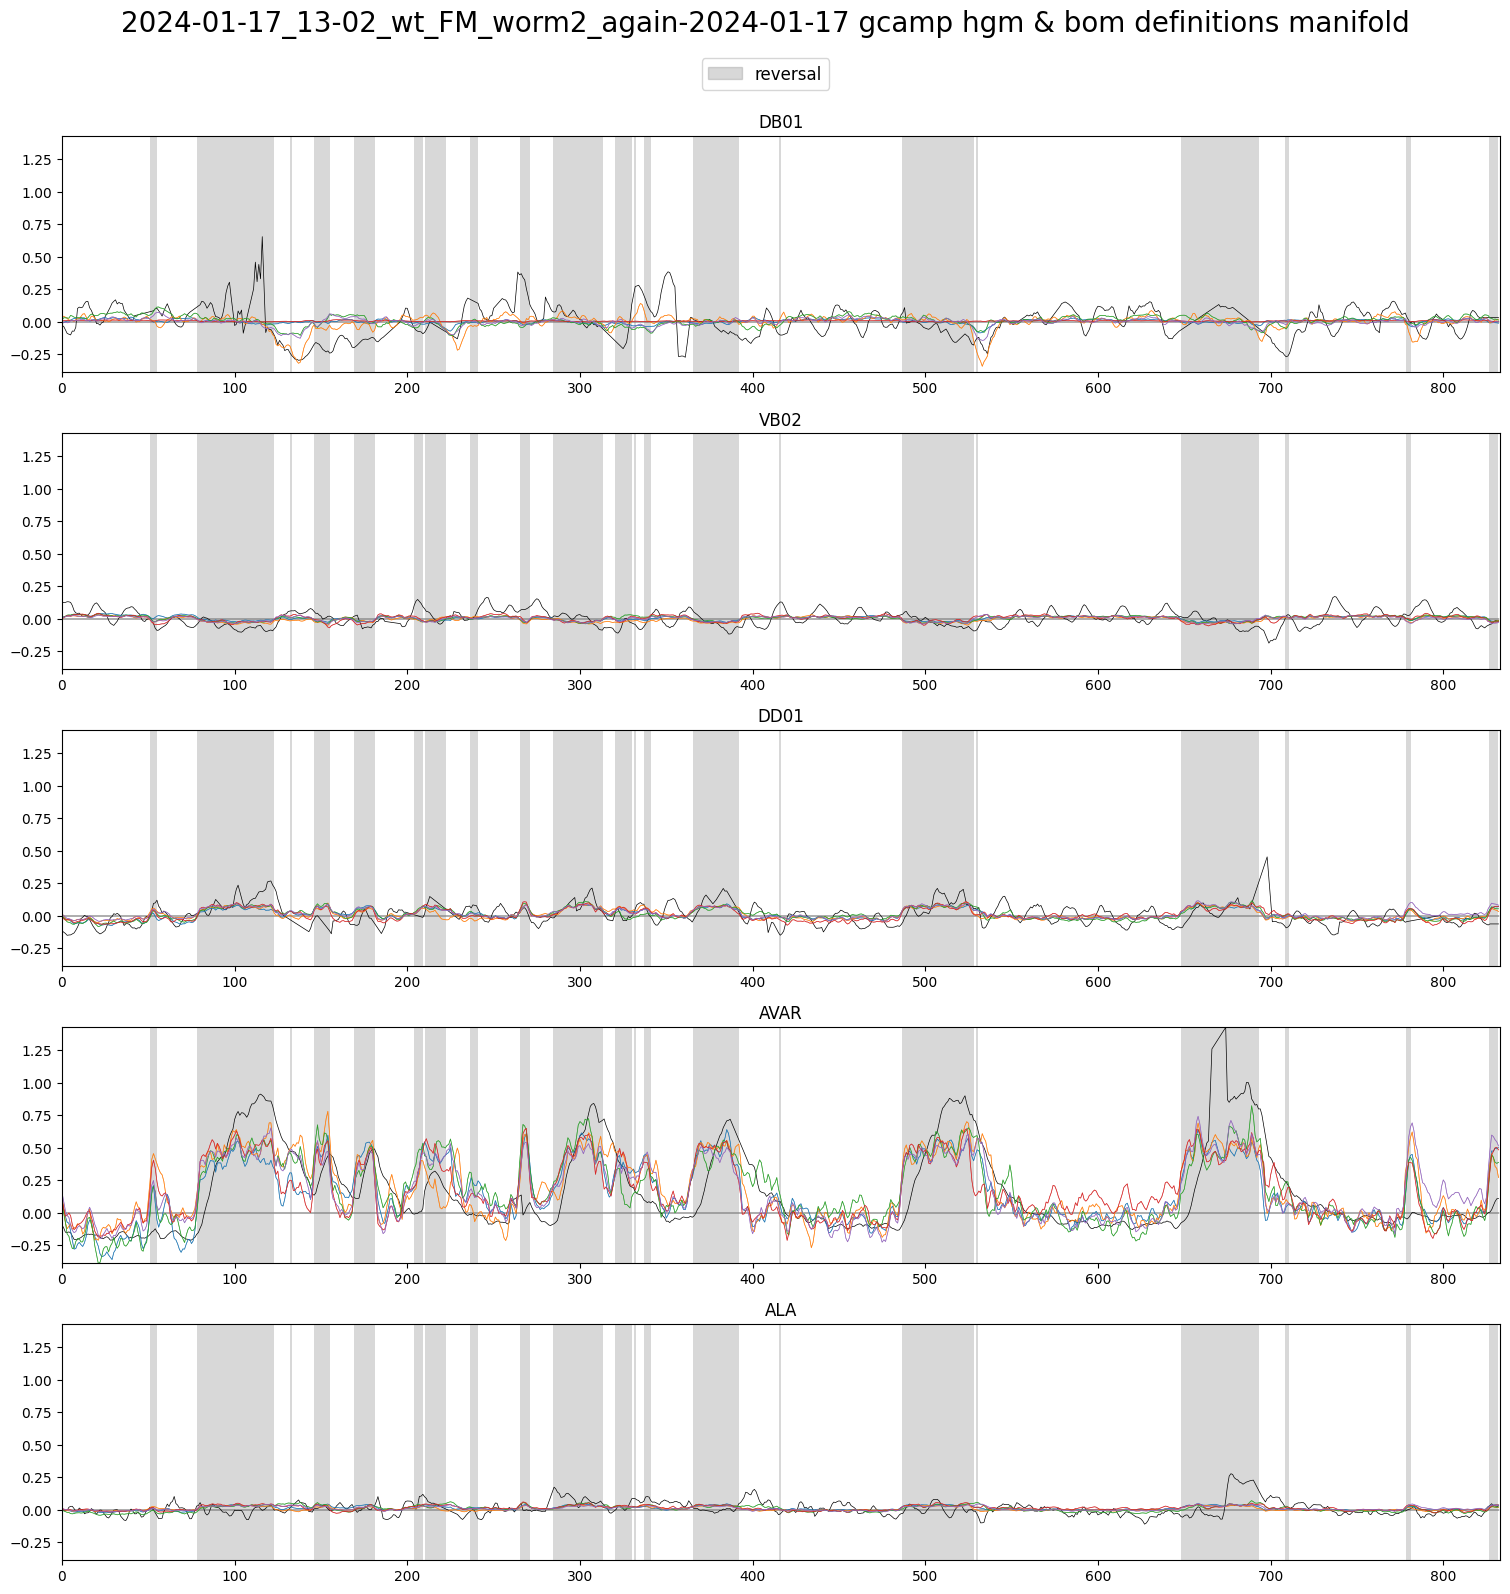

In [42]:
splits = 5
plot_utils.plot_traces_x_splits(
	f'{filenames_gcamp[file_ids_gcamp.index(plot_id)]} gcamp hgm & bom definitions manifold',
	discrete_states_gcamp[file_ids_gcamp.index(plot_id)][['REV']],
	traces_gcamp[file_ids_gcamp.index(plot_id)][selection_n_traces],
	[hgms_rec_gcamp_all[file_ids_gcamp.index(plot_id)][i][selection_n_traces] for i in range(splits)],
	[boms_rec_gcamp_all[file_ids_gcamp.index(plot_id)][i][selection_n_traces] for i in range(splits)],
	plot_first=True, plots_per_row=1, ylimits=None)

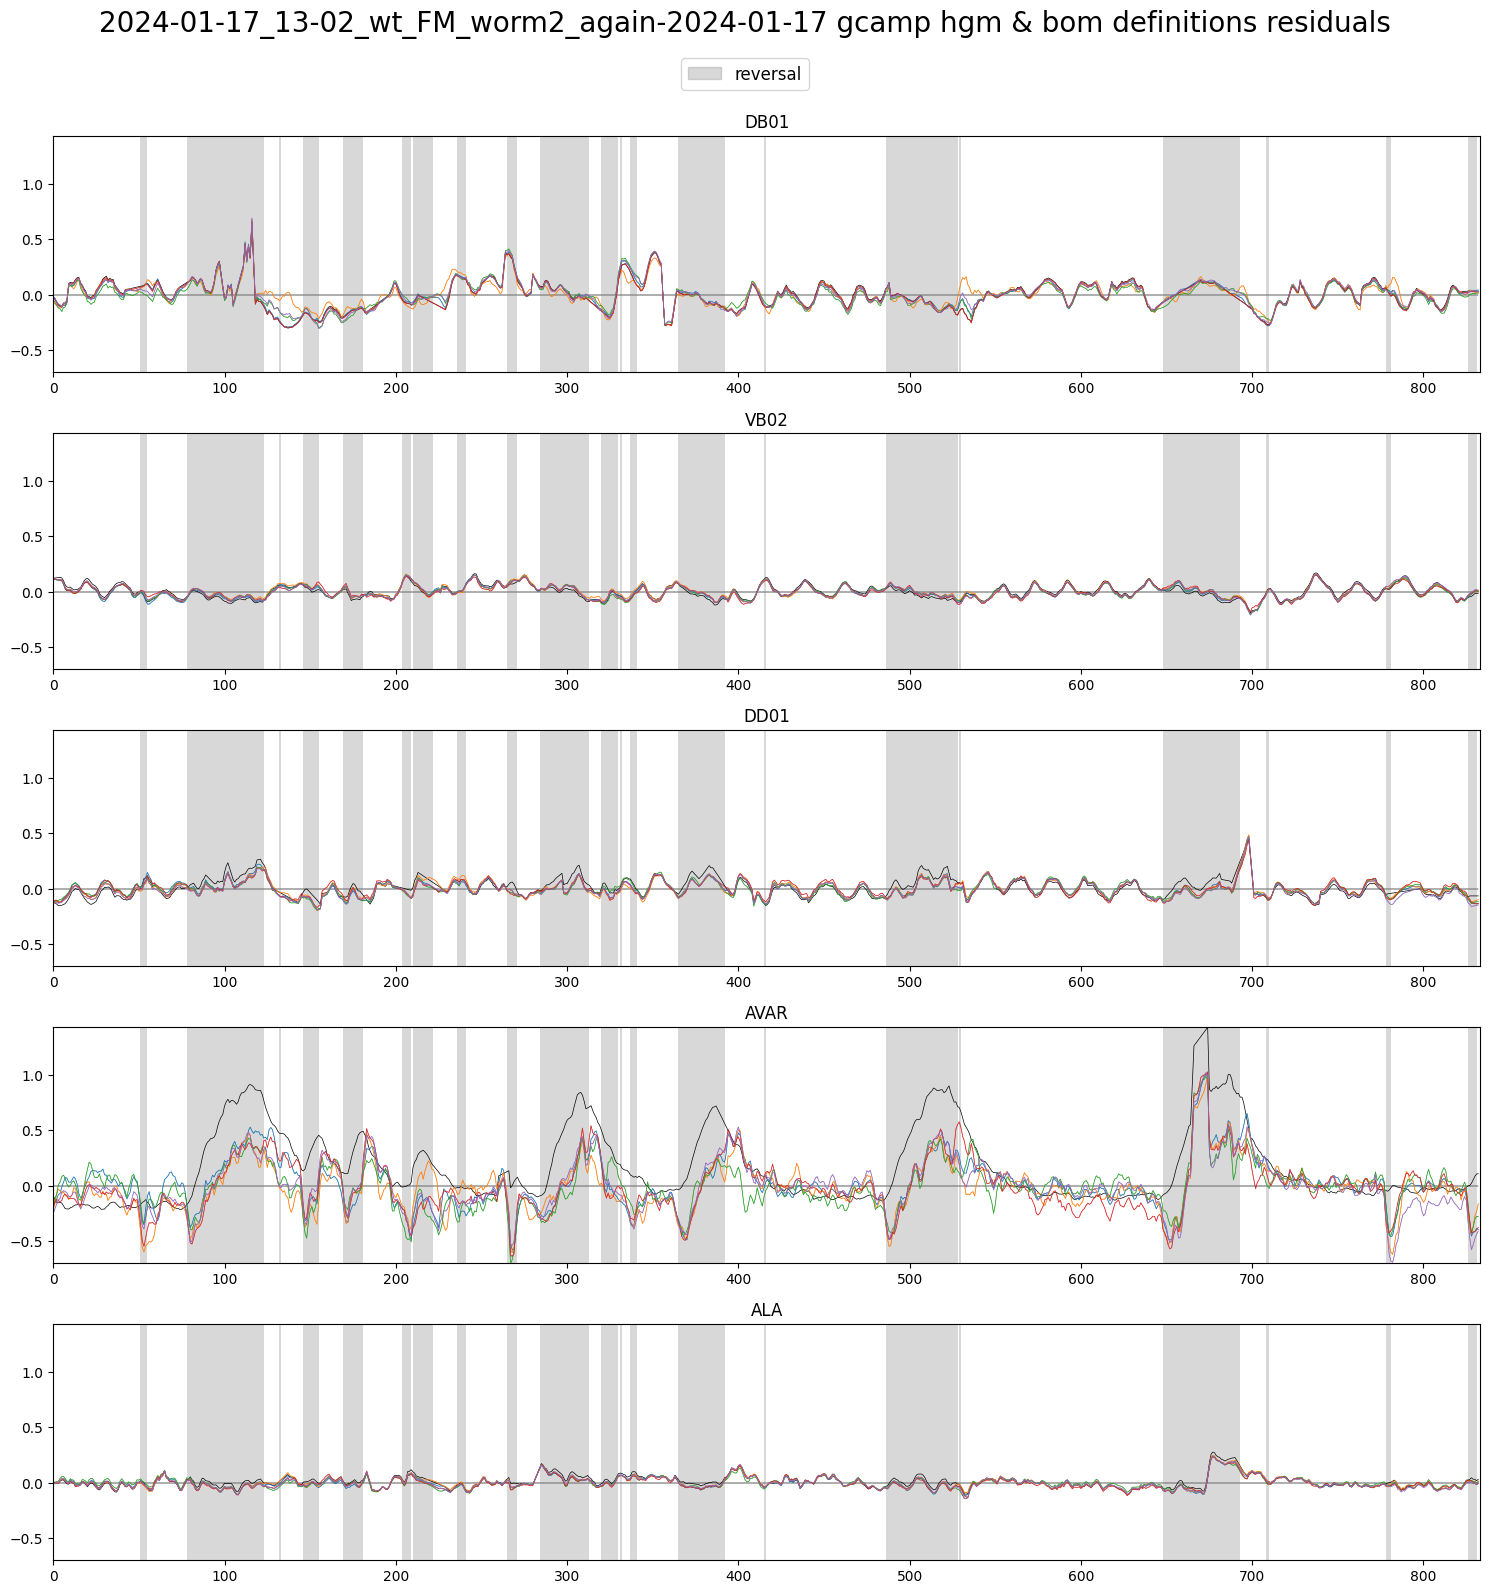

In [43]:
splits = 5
plot_utils.plot_traces_x_splits(
	f'{filenames_gcamp[file_ids_gcamp.index(plot_id)]} gcamp hgm & bom definitions residuals',
	discrete_states_gcamp[file_ids_gcamp.index(plot_id)][['REV']],
	traces_gcamp[file_ids_gcamp.index(plot_id)][selection_n_traces],
	[hgms_res_gcamp_all[file_ids_gcamp.index(plot_id)][i][selection_n_traces] for i in range(splits)],
	[boms_res_gcamp_all[file_ids_gcamp.index(plot_id)][i][selection_n_traces] for i in range(splits)],
	plot_first=True, plots_per_row=1, ylimits=None)

In [ ]:
for i in range(5):
	plot_utils.plot_traces_comparisons(
		f'{filenames_gcamp[file_ids_gcamp.index(plot_id)]} split {i} gcamp hgm & bom predictions residuals',
		discrete_states_gcamp[file_ids_gcamp.index(plot_id)][['REV']],
		traces_gcamp[file_ids_gcamp.index(plot_id)][selection_n_traces],
		[hgms_res_gcamp_all[file_ids_gcamp.index(plot_id)][i][selection_n_traces],
		 hgms_pres_gcamp_all[file_ids_gcamp.index(plot_id)][i][selection_n_traces]],
		[boms_res_gcamp_all[file_ids_gcamp.index(plot_id)][i][selection_n_traces],
		 boms_pres_gcamp_all[file_ids_gcamp.index(plot_id)][i][selection_n_traces]],
		plot_first=False, plots_per_row=1, ylimits=(-0.15, 0.15))

### non IDd neurons

In [ ]:
raise Exception

In [ ]:
n_best = 20

In [ ]:
selection_n_traces_noids = [label for label in selection_n_signi_impr if label[0].isdigit()][:n_best]

In [ ]:
for label in selection_n_traces_noids:
	labels = [label]
	plot_id = int(label.split('_')[0])

	splits = 5
	plot_utils.plot_traces_x_splits(
		f'{filenames_gcamp[file_ids_gcamp.index(plot_id)]} gcamp hgm & bom definitions manifold',
		discrete_states_gcamp[file_ids_gcamp.index(plot_id)]['REV'],
		traces_gcamp[file_ids_gcamp.index(plot_id)][labels],
		[hgms_rec_gcamp_all[file_ids_gcamp.index(plot_id)][i][labels] for i in range(splits)],
		[boms_rec_gcamp_all[file_ids_gcamp.index(plot_id)][i][labels] for i in range(splits)],
		plot_first=True, plots_per_row=1, ylimits=None,
		save_name=f'traces-no-id/{label}-manifolds')

	splits = 5
	plot_utils.plot_traces_x_splits(
		f'{filenames_gcamp[file_ids_gcamp.index(plot_id)]} gcamp hgm & bom definitions residuals',
		discrete_states_gcamp[file_ids_gcamp.index(plot_id)]['REV'],
		traces_gcamp[file_ids_gcamp.index(plot_id)][labels],
		[hgms_res_gcamp_all[file_ids_gcamp.index(plot_id)][i][labels] for i in range(splits)],
		[boms_res_gcamp_all[file_ids_gcamp.index(plot_id)][i][labels] for i in range(splits)],
		plot_first=True, plots_per_row=1, ylimits=None,
		save_name=f'traces-no-id/{label}-residuals')

	for i in range(5):
		plot_utils.plot_traces_comparisons(
			f'{filenames_gcamp[file_ids_gcamp.index(plot_id)]} split {i} gcamp hgm & bom predictions residuals',
			discrete_states_gcamp[file_ids_gcamp.index(plot_id)]['REV'],
			traces_gcamp[file_ids_gcamp.index(plot_id)][labels],
			[hgms_res_gcamp_all[file_ids_gcamp.index(plot_id)][i][labels],
			 hgms_pres_gcamp_all[file_ids_gcamp.index(plot_id)][i][labels]],
			[boms_res_gcamp_all[file_ids_gcamp.index(plot_id)][i][labels],
			 boms_pres_gcamp_all[file_ids_gcamp.index(plot_id)][i][labels]],
			plot_first=False, plots_per_row=1, ylimits=None,
			save_name=f'traces-no-id/{label}-prediction-s{i}')

## Itamar

In [ ]:
raise Exception

In [ ]:
idd = False

selection_n_traces_chosen = sorted([label for label in neuron_scores_gcamp.keys() if label[0].isdigit() is not idd])

high_score_hgm_gfp = np.quantile(np.concatenate([pair[1] for pair in neuron_scores_gfp.values()]), 0.95)
high_score_bom_gfp = np.quantile(np.concatenate([pair[1] for pair in neuron_scores_gfp.values()]), 0.95)

neuron_scores_signficance = dict()
for key in selection_n_traces_chosen:
	scores_glm, scores_hgm = neuron_scores_gcamp[key]
	if len(scores_hgm.shape) == 0:
		scores_glm = scores_glm.reshape(1, 1)
		scores_hgm = scores_hgm.reshape(1, 1)

	neuron_scores_signficance[key] = (np.median(scores_glm) > high_score_hgm_gfp, np.median(scores_hgm) > high_score_hgm_gfp)

neuron_scores_median_impr = {key: np.median(neuron_scores_gcamp[key][1] - neuron_scores_gcamp[key][0]) for key in selection_n_traces_chosen}

In [ ]:
data = [[key,
		 neuron_scores_gcamp[key][0][0][0],
		 neuron_scores_gcamp[key][1][0][0],
		 neuron_scores_signficance[key][0],
		 neuron_scores_signficance[key][1],
		 neuron_scores_median_impr[key]] for key in selection_n_traces_chosen]
if not idd:
	prepend = [filenames_gcamp[file_ids_gcamp.index(int(key.split('_')[0]))] for key in selection_n_traces_chosen]
	for e, p in zip(data, prepend): e.insert(0, p)

df = pd.DataFrame(data, columns=(['Worm'] if not idd else []) + ['Neuron', 'BOM_score', 'HGM_score', 'BOM_score_significant', 'HGM_score_significant', 'HGM-BOM_score_improvement'])
df.to_csv(f'./out/data/{'non' if not idd else ''}id_neurons.csv', index=False)